# Mennatalla: M2 experiment with Google Drive result storage

This repeats the same fixed 120-crop validation experiment and saves each method's
per-crop measurements directly to your Google Drive as execution progresses.
It does not recover missing per-crop measurements from a previous runtime.

1. Run all cells, and authorize the Google Drive connection in the first cell.
2. Select the existing **Mennatalla_M2_Run_Data.zip** when the upload button appears.
3. Wait for **SAVED TO GOOGLE DRIVE**. A new, uniquely named run is created each time.
4. Results remain in **My Drive / C17_Menna_M2_Results / runs**, including the final ZIP.
5. Save the executed notebook too. After a runtime reset, the last download cell can
   reconnect Drive and locate the most recent complete results ZIP without rerunning the filters.

The code and setup are assistant-prepared; record your own observations and checks.
The original submitted reports and historical project results are not replaced.


## Reading this executed notebook

This copy preserves the completed 22 November run. Explanatory comments and this
section were added after execution; the code syntax tree and recorded result
outputs are unchanged. Interactive browser widgets and runtime metadata were
removed for sharing. The exact original notebook is kept locally.

BM3D achieved 38.149 dB / 0.9256 mean SSIM on 120 validation crops; NLM achieved
36.527 dB / 0.9115. In this run the median filter times were 16.821 and 0.515
seconds per crop respectively. These are fresh Colab timings, not the historical
Windows timings. The figure for one crop must not be read as the full-set mean.

The methods use the fixed calibrated parameters. Clean images are scoring
references, not filter inputs. The first visual example follows manifest order.


In [3]:
# Check that Drive can really write and read before starting the long run.
from pathlib import Path
from google.colab import drive
import uuid
drive.mount('/content/drive')
DRIVE_RESULTS = Path('/content/drive/MyDrive/C17_Menna_M2_Results')
DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)
token = uuid.uuid4().hex
probe = DRIVE_RESULTS / ('connection_check_' + token + '.txt')
probe.write_text(token)
if probe.read_text() != token:
    raise RuntimeError('Drive write verification failed; do not start the experiment.')
probe.unlink()
print('PASS: Google Drive write/read check. New results will be saved under:', DRIVE_RESULTS / 'runs')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PASS: Google Drive write/read check. New results will be saved under: /content/drive/MyDrive/C17_Menna_M2_Results/runs


In [4]:
# Keep the recorded library versions with the results; another runtime may differ.
import os
import sys
import subprocess
import importlib.util
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
packages = ['bm3d==4.0.3', 'bm4d==4.2.5', 'scikit-image==0.25.2', 'numpy', 'pillow', 'matplotlib']
if importlib.util.find_spec('torch') is None:
    packages.append('torch')
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *packages])
print('Dependencies ready. Next: choose the validation-data ZIP below.')


Dependencies ready. Next: choose the validation-data ZIP below.


In [5]:
# Verify the supplied input archive before using any of its images or code.
from google.colab import files
from pathlib import Path, PurePosixPath
import hashlib
import io
import json
import stat
import tempfile
import zipfile
print('Choose Mennatalla_M2_Run_Data.zip (not Mennatalla_C17_Files.zip).')
uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError('Upload exactly one validation-data ZIP.')
name, data = next(iter(uploaded.items()))
EXPECTED_SHA = 'f60687266ac3657bb7b030267816a762396697d70ec575b02ff10bbf29acbafe'
if hashlib.sha256(data).hexdigest() != EXPECTED_SHA:
    raise ValueError('Select the exact Mennatalla_M2_Run_Data.zip supplied with this notebook.')
extracted = Path(tempfile.mkdtemp(prefix='menna_m2_run_')).resolve()
with zipfile.ZipFile(io.BytesIO(data)) as archive:
    for item in archive.infolist():
        relative = PurePosixPath(item.filename.replace(chr(92), '/'))
        if (relative.is_absolute() or '..' in relative.parts
                or not (extracted / relative).resolve().is_relative_to(extracted)
                or stat.S_ISLNK(item.external_attr >> 16)):
            raise ValueError('Unsafe ZIP entry')
    if archive.testzip() is not None:
        raise ValueError('Damaged ZIP')
    archive.extractall(extracted)
root = extracted / 'M2_Run'
for relative, expected in json.loads((root / 'FILE_HASHES.json').read_text()).items():
    if hashlib.sha256((root / relative).read_bytes()).hexdigest() != expected:
        raise ValueError('Input file verification failed: ' + relative)
print('PASS: all input images and source files verified.')


Choose Mennatalla_M2_Run_Data.zip (not Mennatalla_C17_Files.zip).


Saving Mennatalla_M2_Run_Data.zip to Mennatalla_M2_Run_Data.zip
PASS: all input images and source files verified.


## Execute the original filters and scoring protocol

The helper below is the same runner as before with one storage change: its output
directory can be supplied explicitly. All filter code, parameters, validation images
and metric definitions are unchanged. CSV snapshots and summaries now go directly to Drive.
Keep the tab open; if Drive reports an error, stop and inspect it instead of assuming a backup exists.


In [6]:
# The filters use noisy images only; clean references are read for scoring.
"""Run the unchanged project baselines on a fresh validation output directory."""
import csv
from datetime import datetime, timezone
import importlib.metadata
import json
from pathlib import Path
import platform
import shutil
import sys
import uuid


def run_validation(root, *, expected_count=120, output_root=None):
    root = Path(root).resolve()
    sys.path.insert(0, str(root / 'src'))
    from c17.data import records, digest, write_json, read_image
    from c17.evaluate import evaluate
    from c17.metrics import score
    import bm3d
    import matplotlib.pyplot as plt
    import numpy as np
    from PIL import Image
    from skimage.restoration import denoise_nl_means

    rows = records(root / 'data/m1', 'val')
    if len(rows) != expected_count:
        raise ValueError(f'Expected {expected_count} validation crops, found {len(rows)}')
    for row in rows:
        for key in ('noisy', 'clean'):
            if not (root / 'data/m1' / row[key]).is_file():
                raise FileNotFoundError(row[key])
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    scope = 'full_validation' if expected_count == 120 else 'smoke_test'
    destination = Path(output_root) if output_root is not None else root / 'personal_runs'
    output = destination / f'menna_{scope}_{stamp}_{uuid.uuid4().hex[:6]}'
    output.mkdir(parents=True, exist_ok=False)
    config = {
        'started_utc': stamp, 'scope': scope, 'count': expected_count,
        'evaluation_only': True, 'training_performed': False,
        'python': platform.python_version(), 'platform': platform.platform(),
        'versions': {name: importlib.metadata.version(name) for name in
                     ('numpy', 'scipy', 'scikit-image', 'pillow', 'matplotlib', 'bm3d', 'bm4d', 'torch')},
        'bm3d_sigma_psd': 0.20,
        'nlm': {'h': 0.08, 'patch_size': 7, 'patch_distance': 11, 'fast_mode': True},
        'threads': 2, 'seed_of_original_split': 681,
        'manifest_sha256': digest(root / 'data/m1/manifest.csv'),
        'source_sha256': {str(p.relative_to(root)): digest(p) for p in (root / 'src/c17').glob('*.py')},
        'scoring': 'RGB float64; exclude 4px border; Gaussian SSIM window 11 sigma 1.5',
        'note': 'Fresh filter evaluation with assistant-prepared code; student interpretation remains to be recorded.'
    }
    write_json(output / 'environment_and_protocol.json', config)
    summaries = []
    for method in ('noisy', 'bm3d', 'nlm'):
        print(f'\nRunning {method.upper()} on {len(rows)} validation crops...', flush=True)
        summary = evaluate(data=root / 'data/m1', output=output / method,
                           method=method, split='val', threads=2)
        assert summary['count'] == len(rows)
        summaries.append(summary)

    columns = ['method', 'count', 'psnr_db', 'ssim', 'median_seconds']
    with (output / 'comparison.csv').open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=columns)
        writer.writeheader()
        writer.writerows({k: row[k] for k in columns} for row in summaries)

    # Display the first manifest crop, chosen before observing scores. These
    # per-image scores are separate from the full validation averages above.
    first = rows[0]
    noisy = read_image(root / 'data/m1' / first['noisy'])
    clean = read_image(root / 'data/m1' / first['clean'])
    bm = np.clip(np.asarray(bm3d.bm3d_rgb(noisy, sigma_psd=.20), dtype=np.float32), 0, 1)
    nlm = np.clip(np.asarray(denoise_nl_means(noisy, h=.08, patch_size=7,
                  patch_distance=11, fast_mode=True, channel_axis=2), dtype=np.float32), 0, 1)
    images = [('Noisy', noisy), ('BM3D', bm), ('NLM', nlm), ('Clean reference', clean)]
    figure, axes = plt.subplots(1, 4, figsize=(14, 4.8))
    for axis, (label, pixels) in zip(axes, images):
        title = label if label == 'Clean reference' else f'{label}\n{score(pixels, clean)[0]:.3f} dB'
        axis.imshow(pixels)
        axis.set_title(title)
        axis.axis('off')
        Image.fromarray((pixels * 255).round().astype('uint8')).save(
            output / (label.lower().replace(' ', '_') + '.png'))
    figure.suptitle('First validation crop: ' + first['id'] + '\nIndividual-crop scores; not the table averages', fontsize=11)
    figure.tight_layout(rect=(0, 0, 1, .86))
    figure.savefig(output / 'before_after.png', dpi=150)
    plt.close(figure)
    figure, axis = plt.subplots(figsize=(7, 4))
    values = [row['psnr_db'] for row in summaries]
    bars = axis.bar(['Noisy', 'BM3D', 'NLM'], values, color=['#94a3b8', '#0072b2', '#d55e00'])
    axis.bar_label(bars, labels=[f'{v:.3f}' for v in values], padding=4)
    axis.set(ylabel='Mean validation PSNR (dB)', ylim=(0, max(values) + 5),
             title=f'Fresh {scope.replace("_", " ")}: {len(rows)} crops')
    figure.tight_layout()
    figure.savefig(output / 'validation_comparison.png', dpi=150)
    plt.close(figure)
    (output / 'MY_REVIEW_NOTES.txt').write_text(
        'Complete this after your own run; do not claim checks you did not do.\n\n'
        'Run date / machine or Colab runtime: PENDING\n'
        'What I executed and observed: PENDING\n'
        'Why clean references are used for scoring only: PENDING\n'
        'Why validation and test scores differ: PENDING\n'
        'Quality versus runtime trade-off: PENDING\n'
        'Unexpected behavior or errors: PENDING\n'
        'Code and setup were assistant-prepared; describe your own work accurately.\n',
        encoding='utf-8')
    config['completed_utc'] = datetime.now(timezone.utc).isoformat()
    config['status'] = 'complete'
    write_json(output / 'environment_and_protocol.json', config)
    archive = Path(shutil.make_archive(str(output), 'zip', root_dir=output))
    print(f'\nCOMPLETE: fresh evaluation on {len(rows)} crops. Results: {archive}', flush=True)
    return output, archive, summaries


In [7]:
# Write this fresh run to Drive so its detailed CSV files survive a runtime reset.
output, result_zip, summaries = run_validation(root, output_root=DRIVE_RESULTS / 'runs')
import zipfile
with zipfile.ZipFile(result_zip) as archive:
    if archive.testzip() is not None:
        raise RuntimeError('Saved result ZIP failed its integrity check.')
print('SAVED TO GOOGLE DRIVE:', result_zip)



Running NOISY on 120 validation crops...
noisy stride=1 val: 1
noisy stride=1 val: 21
noisy stride=1 val: 41
noisy stride=1 val: 61
noisy stride=1 val: 81
noisy stride=1 val: 101
{'method': 'noisy', 'stride': 1, 'split': 'val', 'count': 120, 'threads': 2, 'manifest_sha256': '405739931b1915746af4643b35a59ddaa4293876472c64d43a8346040498099e', 'psnr_db': 28.140915318774898, 'ssim': 0.5132100848097626, 'psnr_std': 5.000735551099482, 'mean_seconds': 0.00019135798333422827, 'median_seconds': 0.0001922965000176191}

Running BM3D on 120 validation crops...
bm3d stride=1 val: 1
bm3d stride=1 val: 21
bm3d stride=1 val: 41
bm3d stride=1 val: 61
bm3d stride=1 val: 81
bm3d stride=1 val: 101
{'method': 'bm3d', 'stride': 1, 'split': 'val', 'count': 120, 'threads': 2, 'manifest_sha256': '405739931b1915746af4643b35a59ddaa4293876472c64d43a8346040498099e', 'psnr_db': 38.148500558174554, 'ssim': 0.9256183084015746, 'psnr_std': 4.769611496680878, 'mean_seconds': 16.880133018999995, 'median_seconds': 16.82

Fresh results: 120 validation crops
Method      PSNR(dB)     SSIM      Median s/crop
noisy         28.141    0.5132          0.000
bm3d          38.149    0.9256         16.821
nlm           36.527    0.9115          0.515


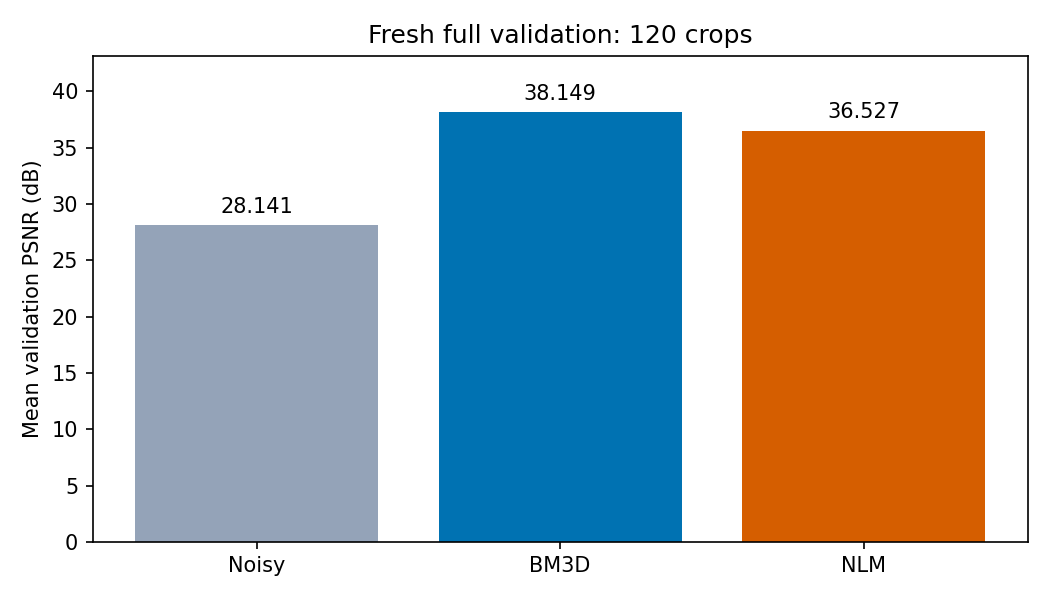

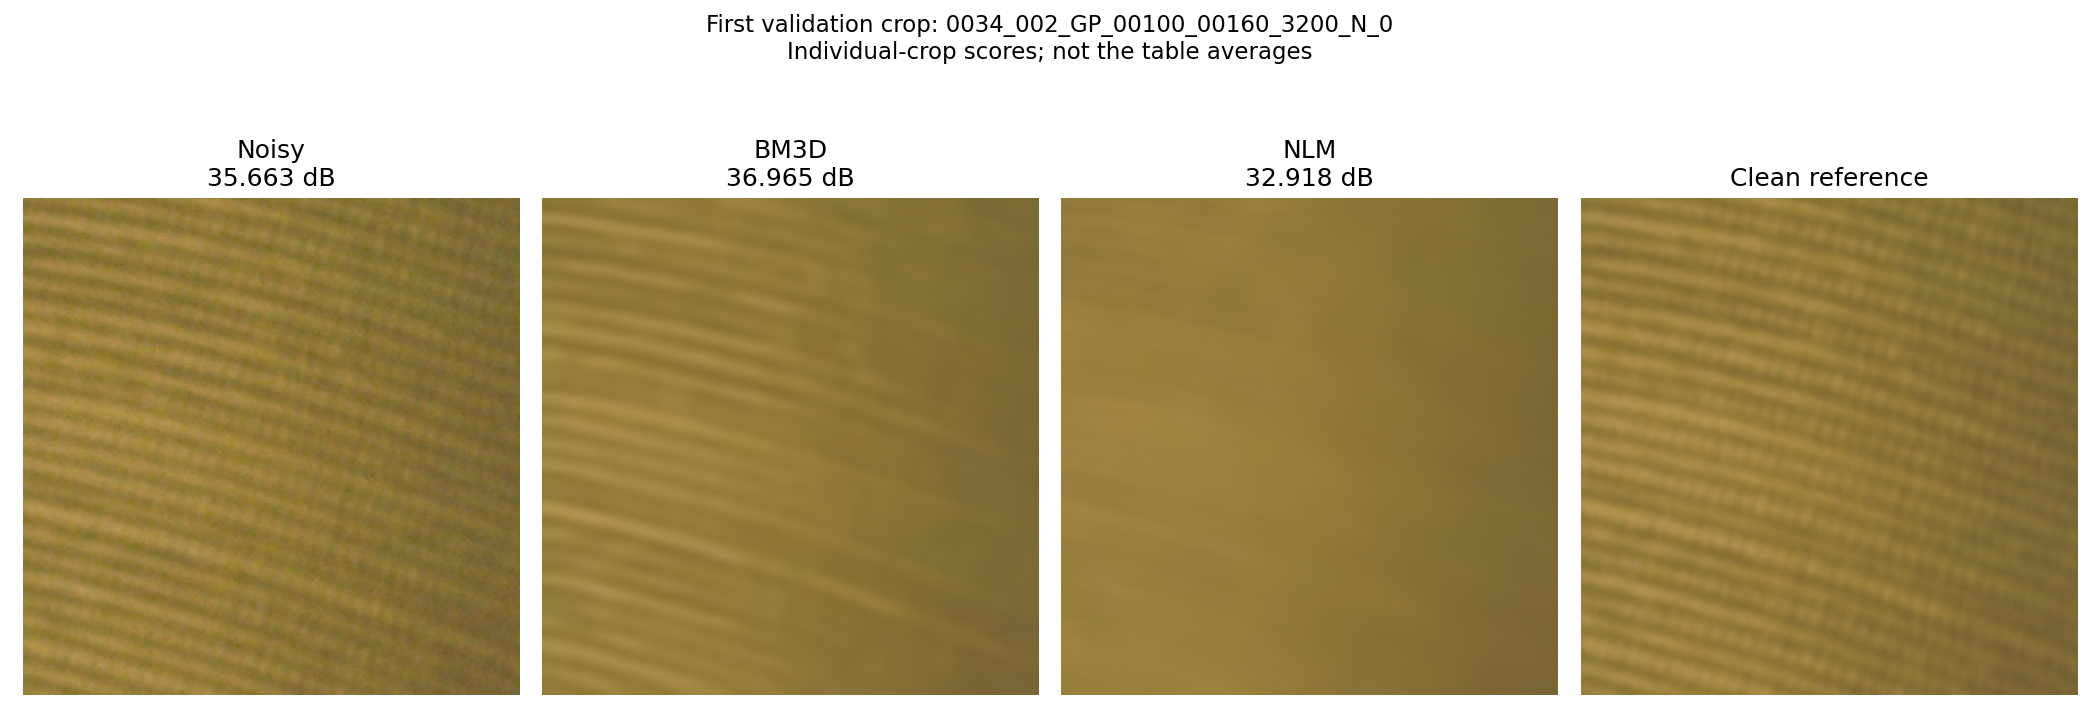

In [8]:
# Table values average 120 crops. The before/after figure describes one crop.
from IPython.display import Image, display
print('Fresh results: 120 validation crops')
print('Method      PSNR(dB)     SSIM      Median s/crop')
for row in summaries:
    print(f"{row['method']:<10} {row['psnr_db']:9.3f}  {row['ssim']:8.4f}  {row['median_seconds']:13.3f}")
display(Image(filename=str(output / 'validation_comparison.png')))
display(Image(filename=str(output / 'before_after.png')))


## Download the latest complete result ZIP (also works after reconnecting)

This cell does not depend on variables created by the experiment cells. It mounts Drive
if needed, checks the newest complete 120-crop ZIP and downloads it. A partial run is
not treated as complete. You can also download the file directly from the Drive website.


In [9]:
# Locate a complete saved ZIP without relying on variables from an old runtime.
from pathlib import Path
from google.colab import drive, files
import json
import zipfile
drive.mount('/content/drive')
folder = Path('/content/drive/MyDrive/C17_Menna_M2_Results/runs')
candidates = sorted(folder.glob('menna_full_validation_*.zip'), key=lambda p: p.stat().st_mtime, reverse=True)
download_path = None
for candidate in candidates:
    try:
        with zipfile.ZipFile(candidate) as archive:
            info = json.loads(archive.read('environment_and_protocol.json'))
            if info.get('status') == 'complete' and info.get('count') == 120 and archive.testzip() is None:
                download_path = candidate
                break
    except (OSError, ValueError, KeyError, zipfile.BadZipFile):
        continue
if download_path is None:
    print('No complete result ZIP found in the Drive results folder. Check the experiment cell for errors.')
else:
    print('Persistent backup:', download_path)
    files.download(str(download_path))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persistent backup: /content/drive/MyDrive/C17_Menna_M2_Results/runs/menna_full_validation_20261122T144408Z_58b9c6.zip


In [10]:
# Diagnostic listing only: this cell does not rerun or delete any experiment.
from pathlib import Path

folder = Path("/content/drive/MyDrive/C17_Menna_M2_Results")
print("Results folder exists:", folder.exists())

runs = sorted((folder / "runs").glob("menna_*"))
print("Run items found:", len(runs))

for run in runs[-5:]:
    print("\n", run.name)
    for file in run.glob("*/per_crop.csv"):
        count = len(file.read_text().splitlines()) - 1
        print(file.parent.name, count, "/ 120")

Results folder exists: True
Run items found: 2

 menna_full_validation_20261122T144408Z_58b9c6
noisy 120 / 120
bm3d 120 / 120
nlm 120 / 120

 menna_full_validation_20261122T144408Z_58b9c6.zip


## Save your notes

Keep the downloaded ZIP and executed notebook. Complete MY_REVIEW_NOTES.txt with what
you actually ran and observed. Do not upload input images, raw datasets or credentials to GitHub.
If a run is interrupted, partial method CSVs may remain in its Drive folder; a fresh Run all
creates a separate experiment, rather than silently combining different runs.

[Colab storage and runtime documentation](https://research.google.com/colaboratory/faq.html).
